In [41]:
# imports
import numpy as np
from time import perf_counter
import matplotlib.pyplot as plt
import pandas as pd

In [25]:
# ex 1
def soft_thresholding(Y, tau):
    U, s, Vt = np.linalg.svd(Y, full_matrices=False)

    s = np.maximum(s - tau, 0)

    return U @ np.diag(s) @ Vt

def SVT(tau, delta, Omega, P_Omega_M, maxit, tol):

    Y = np.zeros_like(P_Omega_M, dtype=float)
    resvec = []

    norm_M = np.linalg.norm(P_Omega_M, "fro")

    if norm_M == 0:
        return Y, np.array([0.0])

    for k in range(maxit):
        X = soft_thresholding(Y, tau)

        R = P_Omega_M - np.where(Omega, X, 0)

        # Calculate the relative residual
        res = np.linalg.norm(R, "fro") / norm_M
        resvec.append(res)

        # Stopping criterion
        if res <= tol:
            break

        Y = Y + delta * R
    
    return X, resvec

In [26]:
M = np.array([
    [4.0, 2.0],
    [2.0, 1.0]
])

Omega = np.array([
    [True, True],
    [True, False]
])

P_Omega_M = np.where(Omega, M, 0)

X, resvec = SVT(
    tau=10,
    delta=1.2,
    Omega=Omega,
    P_Omega_M=P_Omega_M,
    maxit=1000,
    tol=1e-6
)

print("Original matrix:\n", M)
print("Observed matrix:\n", P_Omega_M)
print("Recovered matrix:\n", X)
print("Iterations:", len(resvec))
print("Final residual:", resvec[-1])

Original matrix:
 [[4. 2.]
 [2. 1.]]
Observed matrix:
 [[4. 2.]
 [2. 0.]]
Recovered matrix:
 [[4.00000231 1.99999753]
 [1.99999753 0.99999695]]
Iterations: 51
Final residual: 8.559162059652203e-07


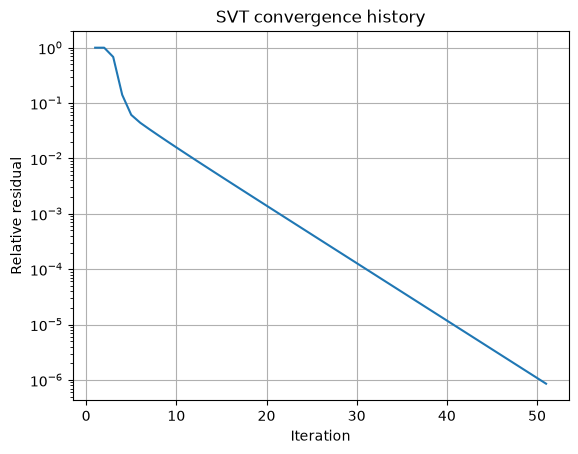

In [27]:
plt.semilogy(
    range(1, len(resvec) + 1),
    resvec
)

plt.xlabel("Iteration")
plt.ylabel("Relative residual")
plt.title("SVT convergence history")
plt.grid(True)
plt.show()

In [28]:
Y = np.array([
    [4, 2],
    [2, 0]
])

tau = 3

U, s, Vt = np.linalg.svd(Y, full_matrices=False)

print("Original singular values:", s)

s = np.maximum(s - tau, 0)

print("New singular values:", s)
print("New diagonal matrix:\n", np.diag(s))

X = U @ np.diag(s) @ Vt

print("Reconstructed matrix:\n", X)

print("Original shape:", Y.shape)
print("Reconstructed shape:", X.shape)

print("Original rank:", np.linalg.matrix_rank(Y))
print("Reconstructed rank:", np.linalg.matrix_rank(X))

Original singular values: [4.82842712 0.82842712]
New singular values: [1.82842712 0.        ]
New diagonal matrix:
 [[1.82842712 0.        ]
 [0.         0.        ]]
Reconstructed matrix:
 [[1.56066017 0.64644661]
 [0.64644661 0.26776695]]
Original shape: (2, 2)
Reconstructed shape: (2, 2)
Original rank: 2
Reconstructed rank: 1


In [34]:
# ex 2
rng = np.random.default_rng(42)

n = 100
r = 3
p = 5
tau = 100

A = rng.standard_normal((n, r))
B = rng.standard_normal((r, n))

M = A @ B

print("Shape:", M.shape)
print("Rank:", np.linalg.matrix_rank(M))

Shape: (100, 100)
Rank: 3


In [ ]:
m = 2 * n * r * p

indices = rng.choice(n * n, size=m, replace=False)

Omega = np.zeros(n * n, dtype=bool)
Omega[indices] = True
Omega = Omega.reshape(n, n)

P_Omega_M = np.where(Omega, M, 0)

print("Omega shape:", Omega.shape)
print("Observed matrix shape:", P_Omega_M.shape)
print("Number of observations:", Omega.sum())
print("Observed fraction:", Omega.mean())

Omega shape: (100, 100)
Observed matrix shape: (100, 100)
Number of observations: 3000
Observed fraction: 0.3


In [36]:
delta = 1.2
maxit = 1000
tol = 1e-5

start = perf_counter()

X, resvec = SVT(
    tau, delta, Omega, P_Omega_M, maxit, tol
)

end = perf_counter()

elapsed_time = end - start

print("Iterations:", len(resvec))
print("Final residual:", resvec[-1])
print("Computational time:", elapsed_time)

Iterations: 1000
Final residual: 0.001136561851075753
Computational time: 0.8421789580006589


In [37]:
error = np.linalg.norm(M - X, "fro") / np.linalg.norm(M, "fro")

print("Reconstruction error:", error)
print("Original rank:", np.linalg.matrix_rank(M))
print("Recovered rank:", np.linalg.matrix_rank(X))

Reconstruction error: 0.18510620117251383
Original rank: 3
Recovered rank: 34


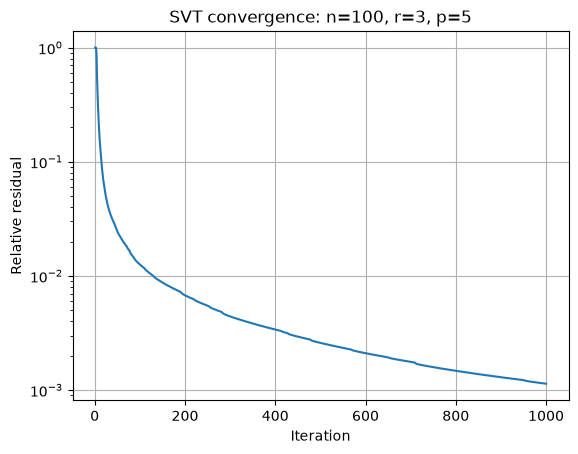

In [38]:
plt.semilogy(
    range(1, len(resvec) + 1),
    resvec
)

plt.xlabel("Iteration")
plt.ylabel("Relative residual")
plt.title(f"SVT convergence: n={n}, r={r}, p={p}")
plt.grid(True)
plt.show()

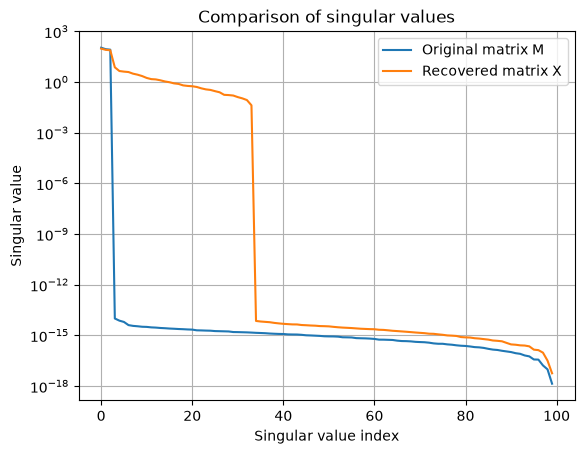

In [39]:
s_M = np.linalg.svd(M, compute_uv=False)
s_X = np.linalg.svd(X, compute_uv=False)

plt.semilogy(s_M, label="Original matrix M")
plt.semilogy(s_X, label="Recovered matrix X")

plt.xlabel("Singular value index")
plt.ylabel("Singular value")
plt.title("Comparison of singular values")
plt.legend()
plt.grid(True)
plt.show()

In [44]:
n_values = [100, 200]
r_values = [3, 4, 5, 6]
p_values = [5, 7]

tau = 100
delta = 1.2
maxit = 1000
tol = 1e-5

results = []
histories = {}
matrices = {}

for n in n_values:
    for r in r_values:

        rng = np.random.default_rng(42)

        A = rng.standard_normal((n, r))
        B = rng.standard_normal((r, n))

        M = A @ B

        matrices[(n, r)] = M

        indices = rng.permutation(n * n)

        for p in p_values:

            m = 2 * n * r * p

            Omega = np.zeros(n * n, dtype=bool)
            Omega[indices[:m]] = True
            Omega = Omega.reshape(n, n)

            P_Omega_M = np.where(Omega, M, 0)

            start = perf_counter()

            X, resvec = SVT(
                tau, delta, Omega,
                P_Omega_M, maxit, tol
            )

            elapsed_time = perf_counter() - start

            error = (
                np.linalg.norm(M - X, "fro")
                / np.linalg.norm(M, "fro")
            )

            histories[(n, r, p)] = resvec

            results.append({
                "n": n,
                "r": r,
                "p": p,
                "observed_fraction": m / n**2,
                "iterations": len(resvec),
                "residual": resvec[-1],
                "error": error,
                "recovered_rank": np.linalg.matrix_rank(X),
                "time": elapsed_time,
                "converged": resvec[-1] <= tol
            })

df = pd.DataFrame(results)

display(df)

,n,r,p,observed_fraction,iterations,residual,error,recovered_rank,time,converged
0,100,3,5,0.30,1000,0.001243,0.164383,33,0.824439,False
1,100,3,7,0.42,1000,0.000246,0.060332,16,0.796061,False
2,100,4,5,0.40,1000,0.000514,0.044132,27,0.810796,False
3,100,4,7,0.56,103,0.000010,0.000021,5,0.081269,True
4,100,5,5,0.50,1000,0.000128,0.003303,15,0.801772,False
5,100,5,7,0.70,55,0.000009,0.000014,5,0.043112,True
6,100,6,5,0.60,327,0.000010,0.000044,12,0.260732,True
7,100,6,7,0.84,36,0.000008,0.000010,6,0.027870,True
8,200,3,5,0.15,1000,0.000189,0.490115,56,2.716439,False
9,200,3,7,0.21,1000,0.000355,0.330647,63,2.746438,False


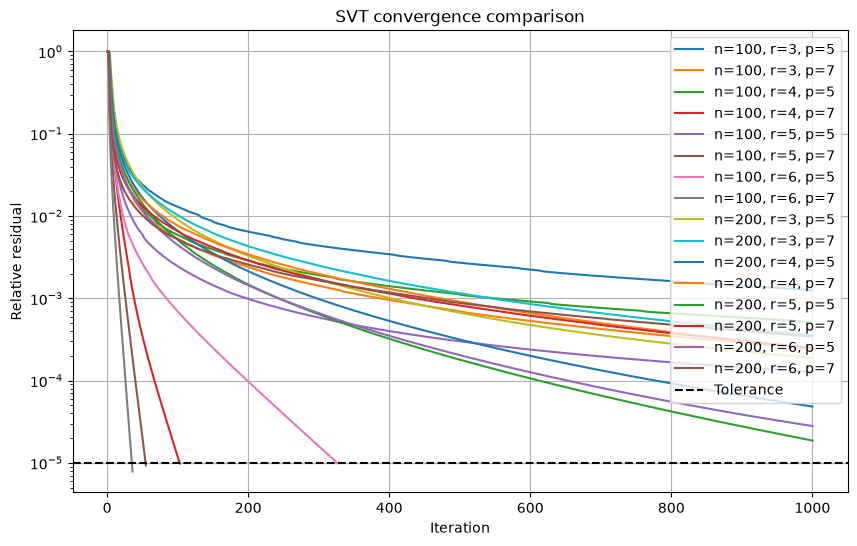

In [45]:
plt.figure(figsize=(10, 6))

for (n, r, p), resvec in histories.items():

    plt.semilogy(
        range(1, len(resvec) + 1),
        resvec,
        label=f"n={n}, r={r}, p={p}"
    )

plt.axhline(
    y=tol,
    color="black",
    linestyle="--",
    label="Tolerance"
)

plt.xlabel("Iteration")
plt.ylabel("Relative residual")
plt.title("SVT convergence comparison")
plt.legend()
plt.grid(True)
plt.show()

In [46]:
def coherence(Q):
    n, r = Q.shape

    row_norms_squared = np.sum(Q**2, axis=1)

    mu = (n / r) * np.max(row_norms_squared)

    return mu

coherence_results = []

for (n, r), M in matrices.items():

    U, s, Vt = np.linalg.svd(M, full_matrices=False)

    U_r = U[:, :r]
    V_r = Vt[:r, :].T

    mu_U = coherence(U_r)
    mu_V = coherence(V_r)

    mu_max = max(mu_U, mu_V)

    coherence_results.append({
        "n": n,
        "r": r,
        "mu_U": mu_U,
        "mu_V": mu_V,
        "mu_max": mu_max
    })

df_coherence = pd.DataFrame(coherence_results)

display(df_coherence)

,n,r,mu_U,mu_V,mu_max
0,100,3,4.526741,3.090118,4.526741
1,100,4,3.417631,4.502825,4.502825
2,100,5,3.097393,3.222963,3.222963
3,100,6,3.276432,2.959593,3.276432
4,200,3,4.841830,4.895796,4.895796
5,200,4,3.753999,3.640500,3.753999
6,200,5,4.594252,3.007257,4.594252
7,200,6,3.058517,2.877936,3.058517


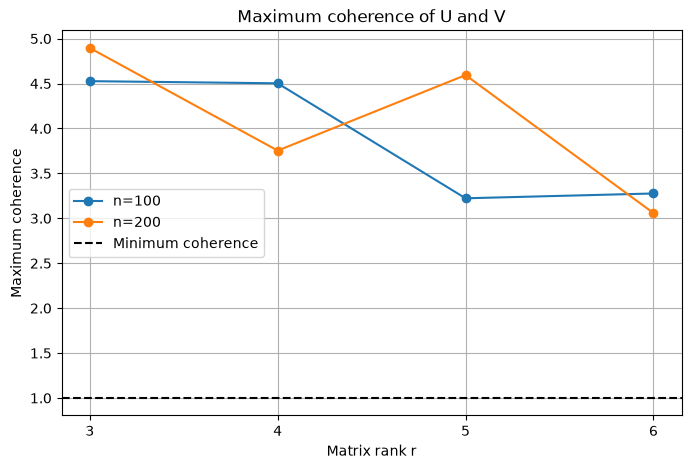

In [47]:
plt.figure(figsize=(8, 5))

for n in n_values:

    subset = df_coherence[df_coherence["n"] == n]

    plt.plot(
        subset["r"],
        subset["mu_max"],
        marker="o",
        label=f"n={n}"
    )

plt.axhline(
    y=1,
    color="black",
    linestyle="--",
    label="Minimum coherence"
)

plt.xlabel("Matrix rank r")
plt.ylabel("Maximum coherence")
plt.title("Maximum coherence of U and V")
plt.xticks(r_values)
plt.legend()
plt.grid(True)
plt.show()